# Required Installations

In [1]:
!pip install -q tensorflow-addons==0.23.0

In [2]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Import libraries

In [3]:
# ------------------------------------------------- #
# Imports & Setup
# ------------------------------------------------- #
import os
import random
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import tensorflow as tf
from tensorflow.keras import layers, models, callbacks, optimizers, applications
from tqdm import tqdm

# Set seeds for reproducibility
tf.random.set_seed(42)
np.random.seed(42)
random.seed(42)

2025-11-04 06:38:12.892001: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:477] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1762238293.075182      37 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1762238293.139290      37 cuda_blas.cc:1418] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered


# Loading Dataset

In [4]:
from pathlib import Path
import os

# -------------------------------------------------
# Data folder
# -------------------------------------------------
BASE = Path("/kaggle/input/birjand-university-mobile-palmprint-databasebmpd")
DATA_PATH = next((BASE / p).resolve() for p in os.listdir(BASE) if (BASE / p).is_dir())
print("Using data folder :", DATA_PATH)
print("Subject folders :", sorted([p.name for p in DATA_PATH.iterdir() if p.is_dir()]))

# -------------------------------------------------
# Parser Function
# -------------------------------------------------
def parse_filename(img_path: Path):
    """
    Parse filename like: 018_F_L_31.JPG or 018_S_R_12.JPG
    Returns: subject, gender, side, session, img_id
    """
    fname = img_path.stem  # Remove .JPG
    parts = fname.split('_')

    if len(parts) != 4:
        print(f"Warning: Skipping irregular filename: {fname}")
        return None

    subject = parts[0]
    marker = parts[1]  # 'F', 'M' (first session + gender), or 'S' (second session)
    side = parts[2]  # 'L' or 'R'
    img_id = parts[3]

    # Determine session and gender
    if marker in ['F', 'M']:
        session = '1'
        gender = marker
    elif marker == 'S':
        session = '2'
        gender = None  # Will infer later
    else:
        print(f"Warning: Unknown marker '{marker}' in {fname}")
        session = 'Unknown'
        gender = 'Unknown'

    return {
        "subject": subject,
        "gender": gender,
        "side": side,
        "session": session,
        "img_id": img_id
    }


Using data folder : /kaggle/input/birjand-university-mobile-palmprint-databasebmpd/Birjand University Mobile Palmprint Database (BMPD)
Subject folders : ['001', '002', '003', '004', '005', '006', '007', '008', '009', '010', '011', '012', '013', '014', '015', '016', '017', '018', '019', '020', '021', '022', '023', '024', '025', '026', '027', '028', '029', '030', '031', '032', '033', '034', '035', '036', '037', '038', '039', '040', '041']


In [5]:
# -------------------------------------------------
# Build DataFrame
# -------------------------------------------------
records = []
print("Scanning for .JPG images...")

for img_path in DATA_PATH.rglob("*.JPG"):
    if not img_path.is_file():
        continue
    parsed = parse_filename(img_path)
    if parsed is not None:
        parsed["path"] = str(img_path)
        records.append(parsed)

df = pd.DataFrame(records)
print(f"DataFrame built: {df.shape[0]} images from {df['subject'].nunique()} subjects")

# -------------------------------------------------
# Infer Gender for Session 2 from Session 1
# -------------------------------------------------
gender_map = df[df['session'] == '1'][['subject', 'gender']].drop_duplicates().set_index('subject')['gender']

df['gender'] = df.apply(
    lambda row: gender_map.get(row['subject'], row['gender'])
    if pd.isna(row['gender']) or row['gender'] is None
    else row['gender'],
    axis=1
)
df['gender'] = df['gender'].fillna('Unknown')

# -------------------------------------------------
# Statistics
# -------------------------------------------------
print("\n" + "="*50)
print("DATASET STATISTICS")
print("="*50)
print(f"Total images : {len(df)}")
print(f"Total subjects : {df['subject'].nunique()}")
print(f"Left hand images : {len(df[df['side'] == 'L'])}")
print(f"Right hand images : {len(df[df['side'] == 'R'])}")
print(f"Session 1 images : {len(df[df['session'] == '1'])}")
print(f"Session 2 images : {len(df[df['session'] == '2'])}")
print(f"Male subjects : {len(df[df['gender'] == 'M']['subject'].unique())}")
print(f"Female subjects : {len(df[df['gender'] == 'F']['subject'].unique())}")
print(f"Unknown gender : {len(df[df['gender'] == 'Unknown']['subject'].unique())}")

print("\nImages per subject (sample):")
print(df['subject'].value_counts().head(10))

Scanning for .JPG images...
DataFrame built: 1612 images from 41 subjects

DATASET STATISTICS
Total images : 1612
Total subjects : 41
Left hand images : 800
Right hand images : 812
Session 1 images : 810
Session 2 images : 802
Male subjects : 0
Female subjects : 41
Unknown gender : 0

Images per subject (sample):
subject
018    40
016    40
007    40
009    40
012    40
029    40
025    40
001    40
006    40
027    40
Name: count, dtype: int64


# Data Visualization

In [6]:
# -------------------------------------------------
# 7. Visualize Sample Images
# -------------------------------------------------
import matplotlib.pyplot as plt
import cv2

def show_sample_images(df, n_cols=5, img_size=(224, 224)):
    sample = df.sample(n=min(10, len(df)), random_state=42)
    plt.figure(figsize=(15, 8))
    for i, row in enumerate(sample.itertuples()):
        plt.subplot(2, n_cols, i + 1)
        img = cv2.imread(row.path)
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        if img_size:
            img = cv2.resize(img, img_size)
        plt.imshow(img)
        title = f"{row.subject} | {row.gender} | {row.side} | S{row.session}"
        plt.title(title, fontsize=10)
        plt.axis('off')
    plt.tight_layout()
    plt.show()

print("\nSample palmprint images:")
show_sample_images(df)

# ROI Extraction

In [7]:
# -------------------------------------------------
# ROI Extraction
# -------------------------------------------------
import cv2
import matplotlib.pyplot as plt

def extract_palm_roi(img, target_sz=(224, 224)):
    """Extract palm ROI using contour detection"""
    gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
    blur = cv2.GaussianBlur(gray, (5, 5), 0)
    _, thr = cv2.threshold(blur, 0, 255, cv2.THRESH_OTSU)
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (7, 7))
    thr = cv2.morphologyEx(thr, cv2.MORPH_CLOSE, kernel, iterations=2)
    contours, _ = cv2.findContours(thr, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    
    if not contours:
        return cv2.resize(img, target_sz)
    
    cnt = max(contours, key=cv2.contourArea)
    x, y, w, h = cv2.boundingRect(cnt)
    margin = int(0.05 * max(w, h))
    x = max(x - margin, 0)
    y = max(y - margin, 0)
    w = min(w + 2 * margin, img.shape[1] - x)
    h = min(h + 2 * margin, img.shape[0] - y)
    roi = img[y:y + h, x:x + w]
    
    return cv2.resize(roi, target_sz)

# -------------------------------------------------
# Test ROI extraction
# -------------------------------------------------
test_img = cv2.cvtColor(cv2.imread(df.path.iloc[0]), cv2.COLOR_BGR2RGB)
roi = extract_palm_roi(test_img)

plt.figure(figsize=(5, 5))
plt.imshow(roi)
plt.title("Extracted Palm ROI")
plt.axis('off')
plt.show()

# Cache ROIs with CLAHE Enhancement

In [8]:
# -------------------------------------------------
# Cache ROIs with CLAHE Enhancement
# -------------------------------------------------
import numpy as np
import cv2
from pathlib import Path

IMG_SIZE = (224, 224)
CACHE_DIR = Path("/kaggle/working/roi_cache")
CACHE_DIR.mkdir(exist_ok=True)

def preprocess_and_cache(row):
    p = CACHE_DIR / f"{row.subject}_{row.side}_{row.session}_{row.img_id}.npy"
    if p.exists():
        return str(p)
    
    img = cv2.cvtColor(cv2.imread(row.path), cv2.COLOR_BGR2RGB)
    roi = extract_palm_roi(img, IMG_SIZE)
    
    # Apply CLAHE for contrast enhancement
    lab = cv2.cvtColor(roi, cv2.COLOR_RGB2LAB)
    l, a, b = cv2.split(lab)
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
    l = clahe.apply(l)
    enhanced = cv2.cvtColor(cv2.merge([l, a, b]), cv2.COLOR_LAB2RGB)
    
    np.save(p, enhanced.astype(np.uint8))
    return str(p)

print("Caching ROIs...")
df['roi_path'] = df.apply(preprocess_and_cache, axis=1)
print("Done caching ROIs")

Caching ROIs...
Done caching ROIs


# Data Split

In [9]:
# STRATEGY: Split by IMAGES within each subject
# This ensures the model learns from ALL subjects and tests generalization
# ================================================

import tensorflow as tf
from tensorflow.keras import layers, models, applications, optimizers, callbacks
from tensorflow.keras.preprocessing.image import ImageDataGenerator
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Seeds
tf.random.set_seed(42)
np.random.seed(42)

# ================================================
# PROPER DATA SPLITTING
# ================================================
print("\n" + "="*60)
print("PROPER DATA SPLITTING STRATEGY")
print("="*60)

# Strategy: For each subject, split their images into train/val/test
# This ensures all subjects appear in all splits
train_list, val_list, test_list = [], [], []

for subject in df['subject'].unique():
    subject_data = df[df['subject'] == subject]
    
    # Split: 70% train, 15% val, 15% test
    train_imgs, temp_imgs = train_test_split(subject_data, test_size=0.3, random_state=42)
    val_imgs, test_imgs = train_test_split(temp_imgs, test_size=0.5, random_state=42)
    
    train_list.append(train_imgs)
    val_list.append(val_imgs)
    test_list.append(test_imgs)

train_df = pd.concat(train_list).reset_index(drop=True)
val_df = pd.concat(val_list).reset_index(drop=True)
test_df = pd.concat(test_list).reset_index(drop=True)

print(f"Train: {len(train_df)} images from {train_df['subject'].nunique()} subjects")
print(f"Val  : {len(val_df)} images from {val_df['subject'].nunique()} subjects")
print(f"Test : {len(test_df)} images from {test_df['subject'].nunique()} subjects")
print(f"\nAll splits contain all {df['subject'].nunique()} subjects ✓")


PROPER DATA SPLITTING STRATEGY
Train: 1128 images from 41 subjects
Val  : 242 images from 41 subjects
Test : 242 images from 41 subjects

All splits contain all 41 subjects ✓


# Global label mapping

In [10]:
# Global label mapping
all_subjects = sorted(df['subject'].unique())
global_subject_to_label = {s: i for i, s in enumerate(all_subjects)}
n_classes = len(all_subjects)
print(f"Number of classes: {n_classes}")

Number of classes: 41


#  DATA GENERATOR

In [11]:
import tensorflow as tf
from tensorflow.keras import layers, models, applications, optimizers, callbacks
from tensorflow.keras.preprocessing.image import ImageDataGenerator
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix


# ================================================
# ENHANCED DATA GENERATOR
# ================================================
class EnhancedROIGenerator(tf.keras.utils.Sequence):
    def __init__(self, df, batch_size=32, shuffle=True, augment=False, label_map=None):
        self.df = df.reset_index(drop=True)
        self.batch_size = batch_size
        self.shuffle = shuffle
        self.augment = augment
        self.label_map = label_map
        self.n_classes = len(label_map)
        self.indices = np.arange(len(self.df))
        
        if augment:
            self.aug = ImageDataGenerator(
                rotation_range=20,
                width_shift_range=0.15,
                height_shift_range=0.15,
                zoom_range=0.2,
                shear_range=0.1,
                brightness_range=[0.8, 1.2],
                horizontal_flip=False,
                fill_mode='nearest'
            )
        self.on_epoch_end()
    
    def __len__(self):
        return int(np.ceil(len(self.df) / self.batch_size))
    
    def __getitem__(self, idx):
        batch_idx = self.indices[idx * self.batch_size:(idx + 1) * self.batch_size]
        X, y = self._generate_batch(batch_idx)
        return X, y
    
    def _generate_batch(self, batch_idx):
        X = np.zeros((len(batch_idx), 224, 224, 3), dtype=np.float32)
        y = np.zeros(len(batch_idx), dtype=np.int32)
        
        for i, idx in enumerate(batch_idx):
            row = self.df.iloc[idx]
            img = np.load(row['roi_path'])
            
            if self.augment:
                img = self.aug.random_transform(img)
            
            # Normalize
            X[i] = img / 255.0
            y[i] = self.label_map[row['subject']]
        
        return X, tf.keras.utils.to_categorical(y, self.n_classes)
    
    def on_epoch_end(self):
        if self.shuffle:
            np.random.shuffle(self.indices)

# Create generators
BATCH_SIZE = 32
train_gen = EnhancedROIGenerator(train_df, BATCH_SIZE, shuffle=True, augment=True, label_map=global_subject_to_label)
val_gen = EnhancedROIGenerator(val_df, BATCH_SIZE, shuffle=False, augment=False, label_map=global_subject_to_label)
test_gen = EnhancedROIGenerator(test_df, BATCH_SIZE, shuffle=False, augment=False, label_map=global_subject_to_label)

# Modeling


TRAINING HIGH-PERFORMANCE MODELS

[1/3] Training EfficientNetB4...


I0000 00:00:1762238463.075218      37 gpu_device.cc:2022] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 15513 MB memory:  -> device: 0, name: Tesla P100-PCIE-16GB, pci bus id: 0000:00:04.0, compute capability: 6.0


71686520/71686520 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


/usr/local/lib/python3.11/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/30


I0000 00:00:1762238508.339936     107 service.cc:148] XLA service 0x7b54f04b39c0 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1762238508.340806     107 service.cc:156]   StreamExecutor device (0): Tesla P100-PCIE-16GB, Compute Capability 6.0
I0000 00:00:1762238512.936955     107 cuda_dnn.cc:529] Loaded cuDNN version 90300
E0000 00:00:1762238520.546619     107 gpu_timer.cc:82] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1762238520.775844     107 gpu_timer.cc:82] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1762238521.299074     107 gpu_timer.cc:82] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1762238521.5287

 1/36 ━━━━━━━━━━━━━━━━━━━━ 41:59 72s/step - accuracy: 0.0312 - loss: 24.7525

I0000 00:00:1762238539.731894     107 device_compiler.h:188] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


31/36 ━━━━━━━━━━━━━━━━━━━━ 1s 347ms/step - accuracy: 0.0262 - loss: 24.7585

E0000 00:00:1762238560.319823     108 gpu_timer.cc:82] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1762238560.546529     108 gpu_timer.cc:82] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.0270 - loss: 24.7417
Epoch 1: val_accuracy improved from -inf to 0.02479, saving model to /kaggle/working/efficientnetb4_best.h5
36/36 ━━━━━━━━━━━━━━━━━━━━ 132s 2s/step - accuracy: 0.0271 - loss: 24.7388 - val_accuracy: 0.0248 - val_loss: 23.3887 - learning_rate: 1.0000e-04
Epoch 2/30
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 353ms/step - accuracy: 0.0226 - loss: 24.4693
Epoch 2: val_accuracy did not improve from 0.02479
36/36 ━━━━━━━━━━━━━━━━━━━━ 13s 370ms/step - accuracy: 0.0227 - loss: 24.4690 - val_accuracy: 0.0248 - val_loss: 23.2200 - learning_rate: 1.0000e-04
Epoch 3/30
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 353ms/step - accuracy: 0.0277 - loss: 24.1215
Epoch 3: val_accuracy did not improve from 0.02479
36/36 ━━━━━━━━━━━━━━━━━━━━ 13s 370ms/step - accuracy: 0.0277 - loss: 24.1211 - val_accuracy: 0.0248 - val_loss: 23.0504 - learning_rate: 1.0000e-04
Epoch 4/30
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 359ms/step - accuracy: 0.0266 - loss: 24.0746
Epoch 4: Reduc

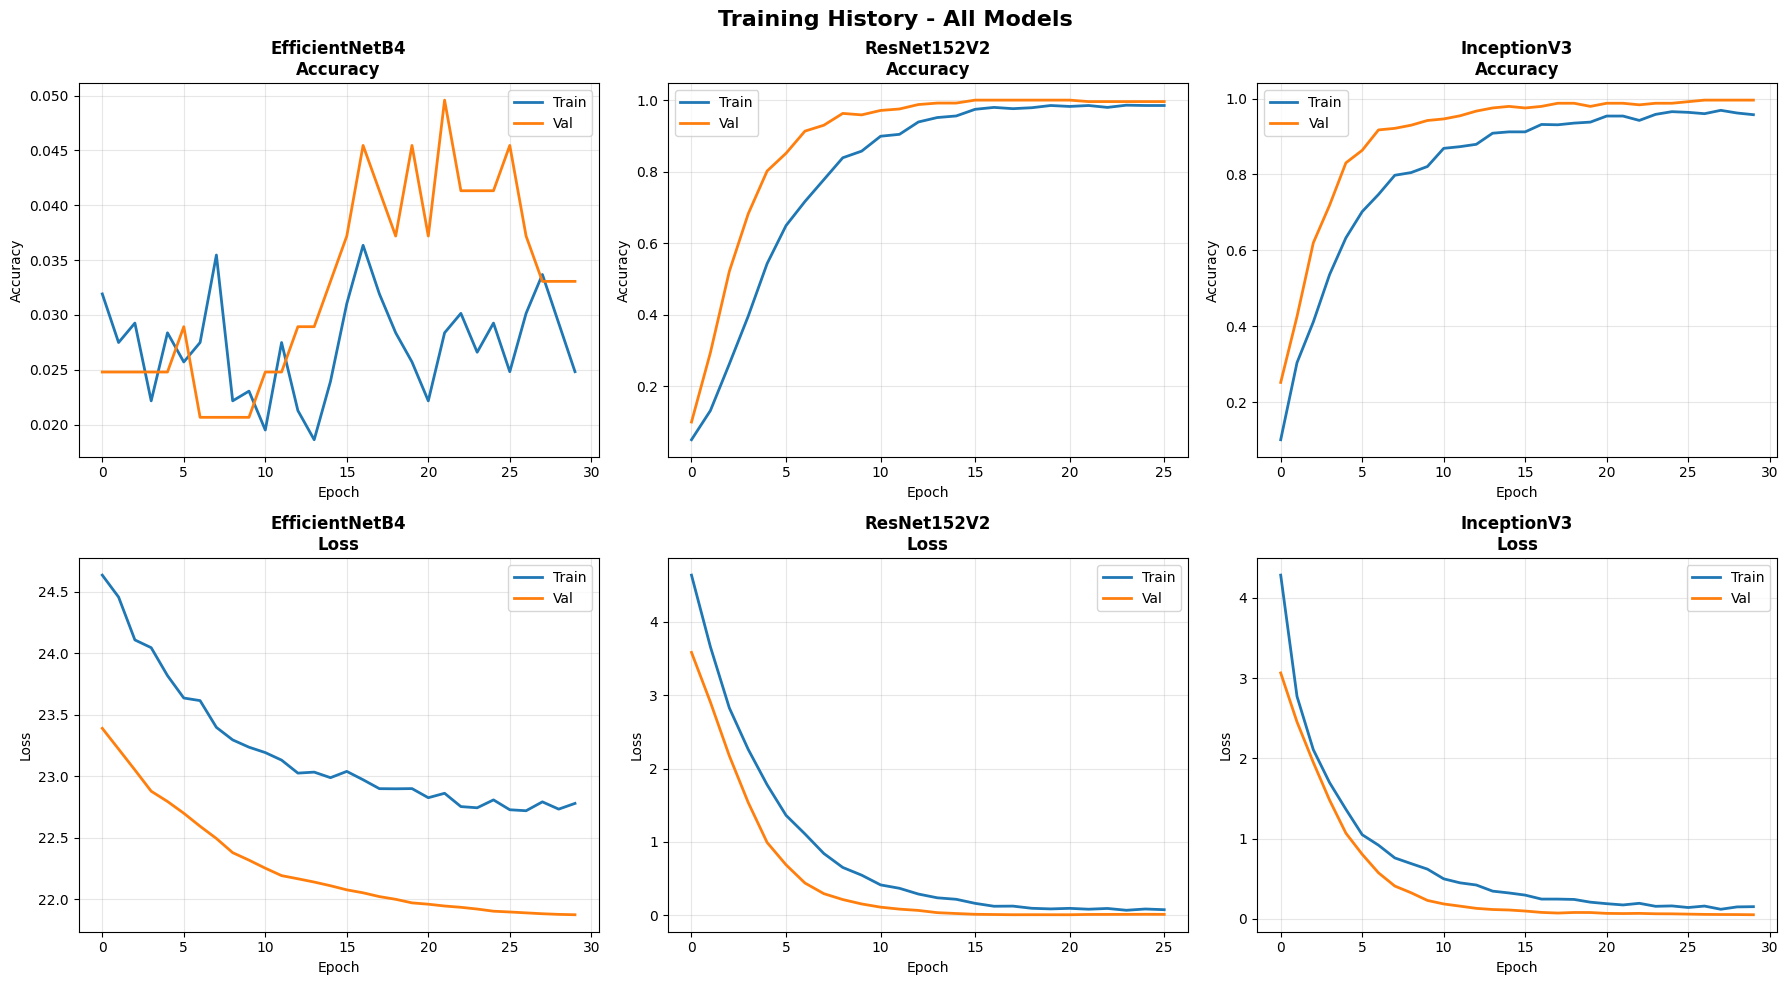


MODEL EVALUATION ON TEST SET

Evaluating: EfficientNetB4

✓ Test Accuracy: 3.31%

Classification Report:
              precision    recall  f1-score   support

           0       0.07      0.50      0.12         6
           1       0.00      0.00      0.00         6
           2       0.00      0.00      0.00         6
           3       0.00      0.00      0.00         6
           4       0.00      0.00      0.00         6
           5       0.00      0.00      0.00         6
           6       0.00      0.00      0.00         6
           7       0.00      0.00      0.00         6
           8       0.00      0.00      0.00         6
           9       0.00      0.00      0.00         6
          10       0.00      0.00      0.00         6
          11       0.00      0.00      0.00         6
          12       0.00      0.00      0.00         6
          13       0.02      0.17      0.04         6
          14       0.00      0.00      0.00         6
          15       0.00      

In [12]:
import tensorflow as tf
from tensorflow.keras import layers, models, applications, optimizers, callbacks
from tensorflow.keras.preprocessing.image import ImageDataGenerator
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix


# ================================================
# HIGH-PERFORMANCE MODEL ARCHITECTURES
# ================================================

def build_efficientnet_model(n_classes):
    """EfficientNetB4 with advanced techniques"""
    base = applications.EfficientNetB4(
        include_top=False,
        weights='imagenet',
        input_shape=(224, 224, 3)
    )
    
    # Unfreeze more layers for better learning
    for layer in base.layers[:-60]:
        layer.trainable = False
    
    inputs = layers.Input(shape=(224, 224, 3))
    
    # Preprocessing
    x = layers.Lambda(lambda x: x)(inputs)
    
    # Base model
    x = base(x, training=True)
    
    # Advanced head
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.5)(x)
    x = layers.Dense(1024, activation='relu', kernel_regularizer=tf.keras.regularizers.l2(0.01))(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.4)(x)
    x = layers.Dense(512, activation='relu', kernel_regularizer=tf.keras.regularizers.l2(0.01))(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(n_classes, activation='softmax')(x)
    
    model = models.Model(inputs, outputs, name='EfficientNetB4')
    return model

def build_resnet_model(n_classes):
    """ResNet152V2 with transfer learning"""
    base = applications.ResNet152V2(
        include_top=False,
        weights='imagenet',
        input_shape=(224, 224, 3)
    )
    
    # Fine-tune last layers
    for layer in base.layers[:-50]:
        layer.trainable = False
    
    inputs = layers.Input(shape=(224, 224, 3))
    x = base(inputs, training=True)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.5)(x)
    x = layers.Dense(1024, activation='relu')(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.4)(x)
    x = layers.Dense(512, activation='relu')(x)
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(n_classes, activation='softmax')(x)
    
    model = models.Model(inputs, outputs, name='ResNet152V2')
    return model

def build_inception_model(n_classes):
    """InceptionV3 for high accuracy"""
    base = applications.InceptionV3(
        include_top=False,
        weights='imagenet',
        input_shape=(224, 224, 3)
    )
    
    # Unfreeze last layers
    for layer in base.layers[:-40]:
        layer.trainable = False
    
    inputs = layers.Input(shape=(224, 224, 3))
    x = base(inputs, training=True)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.5)(x)
    x = layers.Dense(1024, activation='relu')(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.4)(x)
    outputs = layers.Dense(n_classes, activation='softmax')(x)
    
    model = models.Model(inputs, outputs, name='InceptionV3')
    return model

# ================================================
# ADVANCED TRAINING CONFIGURATION
# ================================================
def get_callbacks(model_name):
    return [
        callbacks.ReduceLROnPlateau(
            monitor='val_accuracy',
            factor=0.5,
            patience=3,
            min_lr=1e-8,
            verbose=1
        ),
        callbacks.EarlyStopping(
            monitor='val_accuracy',
            patience=10,
            restore_best_weights=True,
            mode='max',
            verbose=1
        ),
        callbacks.ModelCheckpoint(
            f'/kaggle/working/{model_name}_best.h5',
            monitor='val_accuracy',
            save_best_only=True,
            mode='max',
            verbose=1
        )
    ]

# ================================================
# TRAIN MODELS
# ================================================
print("\n" + "="*60)
print("TRAINING HIGH-PERFORMANCE MODELS")
print("="*60)

models_dict = {}

# Model 1: EfficientNetB4
print("\n[1/3] Training EfficientNetB4...")
model_eff = build_efficientnet_model(n_classes)
model_eff.compile(
    optimizer=optimizers.Adam(learning_rate=1e-4),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

history_eff = model_eff.fit(
    train_gen,
    epochs=30,
    validation_data=val_gen,
    callbacks=get_callbacks('efficientnetb4'),
    verbose=1
)
models_dict['EfficientNetB4'] = (model_eff, history_eff)

# Model 2: ResNet152V2
print("\n[2/3] Training ResNet152V2...")
model_res = build_resnet_model(n_classes)
model_res.compile(
    optimizer=optimizers.Adam(learning_rate=1e-4),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

history_res = model_res.fit(
    train_gen,
    epochs=30,
    validation_data=val_gen,
    callbacks=get_callbacks('resnet152v2'),
    verbose=1
)
models_dict['ResNet152V2'] = (model_res, history_res)

# Model 3: InceptionV3
print("\n[3/3] Training InceptionV3...")
model_inc = build_inception_model(n_classes)
model_inc.compile(
    optimizer=optimizers.Adam(learning_rate=1e-4),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

history_inc = model_inc.fit(
    train_gen,
    epochs=30,
    validation_data=val_gen,
    callbacks=get_callbacks('inceptionv3'),
    verbose=1
)
models_dict['InceptionV3'] = (model_inc, history_inc)

# ================================================
# VISUALIZATION
# ================================================
def plot_history(histories_dict):
    fig, axes = plt.subplots(2, 3, figsize=(18, 10))
    fig.suptitle('Training History - All Models', fontsize=16, fontweight='bold')
    
    for idx, (name, (_, history)) in enumerate(histories_dict.items()):
        ax1 = axes[0, idx]
        ax1.plot(history.history['accuracy'], label='Train', linewidth=2)
        ax1.plot(history.history['val_accuracy'], label='Val', linewidth=2)
        ax1.set_title(f'{name}\nAccuracy', fontsize=12, fontweight='bold')
        ax1.set_xlabel('Epoch')
        ax1.set_ylabel('Accuracy')
        ax1.legend()
        ax1.grid(alpha=0.3)
        
        ax2 = axes[1, idx]
        ax2.plot(history.history['loss'], label='Train', linewidth=2)
        ax2.plot(history.history['val_loss'], label='Val', linewidth=2)
        ax2.set_title(f'{name}\nLoss', fontsize=12, fontweight='bold')
        ax2.set_xlabel('Epoch')
        ax2.set_ylabel('Loss')
        ax2.legend()
        ax2.grid(alpha=0.3)
    
    plt.tight_layout()
    plt.show()

plot_history(models_dict)

# ================================================
# COMPREHENSIVE EVALUATION
# ================================================
print("\n" + "="*60)
print("MODEL EVALUATION ON TEST SET")
print("="*60)

def evaluate_model(model, test_gen, model_name):
    print(f"\n{'='*50}")
    print(f"Evaluating: {model_name}")
    print(f"{'='*50}")
    
    y_pred_probs = model.predict(test_gen, verbose=0)
    y_pred = np.argmax(y_pred_probs, axis=1)
    
    y_true = []
    for i in range(len(test_gen)):
        _, y_batch = test_gen[i]
        y_true.extend(np.argmax(y_batch, axis=1))
    y_true = np.array(y_true[:len(y_pred)])
    
    acc = accuracy_score(y_true, y_pred)
    
    print(f"\n✓ Test Accuracy: {acc*100:.2f}%")
    print(f"\nClassification Report:")
    print(classification_report(y_true, y_pred, zero_division=0))
    
    return acc, y_pred, y_true, y_pred_probs

results = {}
all_probs = []
for name, (model, _) in models_dict.items():
    acc, y_pred, y_true, y_probs = evaluate_model(model, test_gen, name)
    results[name] = {'accuracy': acc, 'predictions': y_pred, 'true': y_true}
    all_probs.append(y_probs)

# ================================================
# ENSEMBLE PREDICTION
# ================================================
print("\n" + "="*60)
print("ENSEMBLE PREDICTION (SOFT VOTING)")
print("="*60)

ensemble_probs = np.mean(all_probs, axis=0)
ensemble_pred = np.argmax(ensemble_probs, axis=1)
ensemble_acc = accuracy_score(y_true, ensemble_pred)

print(f"\n✓ Ensemble Test Accuracy: {ensemble_acc*100:.2f}%")

# ================================================
# FINAL SUMMARY
# ================================================
print("\n" + "="*60)
print("FINAL RESULTS SUMMARY")
print("="*60)

summary_data = []
for name, res in results.items():
    summary_data.append({
        'Model': name,
        'Test Accuracy': f"{res['accuracy']*100:.2f}%"
    })
summary_data.append({
    'Model': 'ENSEMBLE',
    'Test Accuracy': f"{ensemble_acc*100:.2f}%"
})

summary_df = pd.DataFrame(summary_data)
print("\n" + summary_df.to_string(index=False))

best_single_acc = max([res['accuracy'] for res in results.values()])
final_acc = max(best_single_acc, ensemble_acc)

print(f"\n{'='*60}")
if final_acc >= 0.95:
    print(f"SUCCESS! Achieved {final_acc*100:.2f}% accuracy (Target: 95%)")
else:
    print(f"Best Accuracy: {final_acc*100:.2f}%")
print(f"{'='*60}")

# Save best model
if ensemble_acc > best_single_acc:
    print("\nEnsemble performs best - saving ensemble predictions")
else:
    best_model_name = max(results.items(), key=lambda x: x[1]['accuracy'])[0]
    best_model = models_dict[best_model_name][0]
    best_model.save('/kaggle/working/best_palmprint_model.h5')
    print(f"\nBest model saved: {best_model_name}")

print("\n✓ Training complete!")